In [1]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import requests
import sys
from tqdm import tqdm
import os
%matplotlib inline

In [2]:
prometheus_endpoint = 'hal.sage.ieat.ro'
prometheus_port = '9090'
print("Collecting data from Monitoring at: {}".format(prometheus_endpoint))
#https://prometheus.io/docs/prometheus/latest/querying/basics/
prometheus_query = {"query": '''{__name__=~"node.+"}[20m]'''}
try:
    url = '/api/v1/query'
    resp = requests.get('http://{}:{}{}'.format(prometheus_endpoint, prometheus_port, url), params=prometheus_query)
except Exception as inst:
    print("Error fetching data")

In [3]:
# resp.json()["data"]['result']

In [4]:
def prtoDF(data,
           verbose=False,
           index=None):
    """
    From PR backend to dataframe
    :param data: PR response JSON
    :return: dataframe
    """
    if not data:
        print("No data has been received!")
        sys.exit(2)
    df = pd.DataFrame()
    df_time = pd.DataFrame()
    if verbose:
        dr = tqdm(data['data']['result'])
    else:
        dr = data['data']['result']
    for el in dr:
        metric_name = el['metric']['__name__']
        instance_name = el['metric']['instance']
        new_metric = "{}_{}".format(metric_name, instance_name)
        values = el['values']
        proc_val = []
        proc_time = []
        for val in values:
            proc_val.append(val[1])
            proc_time.append(val[0])
        df[new_metric] = proc_val
        time_new_metric = "time_{}".format(new_metric)
        df_time[time_new_metric] = proc_time
    # Calculate the meant time for all metrics
    df_time['mean'] = df_time.mean(axis=1)
    # Round to np.ceil all metrics
    df_time['mean'] = df_time['mean'].apply(np.ceil)
    # Add the meant time to rest of metrics
    df['time'] = df_time['mean']
    print("[INFO] PR query resulted in dataframe of size: {}".format(df.shape))
    if index is not None:
        df.set_index(index, inplace=True)
        print('[WARN] PR query dataframe index set to  {}'.format( index))
    return df

df_bd_lab = prtoDF(resp.json(), verbose=True, index='time')

100%|██████████| 408/408 [00:00<00:00, 3170.56it/s]

[INFO] PR query resulted in dataframe of size: (1194, 194)
[WARN] PR query dataframe index set to  time


In [5]:
df_bd_lab = df_bd_lab.astype(np.float64)

In [6]:
df_bd_lab

,node_arp_entries_192.168.56.2:9100,node_boot_time_seconds_192.168.56.2:9100,node_context_switches_total_192.168.56.2:9100,node_cpu_guest_seconds_total_192.168.56.2:9100,node_cpu_seconds_total_192.168.56.2:9100,node_disk_io_now_192.168.56.2:9100,node_disk_io_time_seconds_total_192.168.56.2:9100,node_disk_io_time_weighted_seconds_total_192.168.56.2:9100,node_disk_read_bytes_total_192.168.56.2:9100,node_disk_read_time_seconds_total_192.168.56.2:9100,...,node_timex_tai_offset_seconds_192.168.56.2:9100,node_timex_tick_seconds_192.168.56.2:9100,node_uname_info_192.168.56.2:9100,node_vmstat_oom_kill_192.168.56.2:9100,node_vmstat_pgfault_192.168.56.2:9100,node_vmstat_pgmajfault_192.168.56.2:9100,node_vmstat_pgpgin_192.168.56.2:9100,node_vmstat_pgpgout_192.168.56.2:9100,node_vmstat_pswpin_192.168.56.2:9100,node_vmstat_pswpout_192.168.56.2:9100
time,,,,,,,,,,,,,,,,,,,,,
1.700757e+09,1.0,1.700750e+09,5687539.0,0.0,24.71,0.0,0.016,0.016,2080256.0,0.016,...,0.0,0.01,1.0,0.0,8095040.0,3822.0,2260377.0,10577852.0,0.0,0.0
1.700757e+09,1.0,1.700750e+09,5687855.0,0.0,24.71,0.0,0.016,0.016,2080256.0,0.016,...,0.0,0.01,1.0,0.0,8095040.0,3822.0,2260377.0,10577852.0,0.0,0.0
1.700757e+09,1.0,1.700750e+09,5688132.0,0.0,24.71,0.0,0.016,0.016,2080256.0,0.016,...,0.0,0.01,1.0,0.0,8095040.0,3822.0,2260377.0,10577852.0,0.0,0.0
1.700757e+09,1.0,1.700750e+09,5688375.0,0.0,24.71,0.0,0.016,0.016,2080256.0,0.016,...,0.0,0.01,1.0,0.0,8095040.0,3822.0,2260377.0,10577852.0,0.0,0.0
1.700757e+09,1.0,1.700750e+09,5688703.0,0.0,24.71,0.0,0.016,0.016,2080256.0,0.016,...,0.0,0.01,1.0,0.0,8095040.0,3822.0,2260377.0,10577852.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1.700758e+09,1.0,1.700750e+09,6067408.0,0.0,27.41,0.0,0.016,0.016,2080256.0,0.016,...,0.0,0.01,1.0,0.0,8651306.0,4326.0,2357537.0,10586784.0,0.0,0.0
1.700758e+09,1.0,1.700750e+09,6067725.0,0.0,27.41,0.0,0.016,0.016,2080256.0,0.016,...,0.0,0.01,1.0,0.0,8651306.0,4326.0,2357537.0,10586784.0,0.0,0.0
1.700758e+09,1.0,1.700750e+09,6067984.0,0.0,27.41,0.0,0.016,0.016,2080256.0,0.016,...,0.0,0.01,1.0,0.0,8651306.0,4326.0,2357537.0,10586784.0,0.0,0.0


<AxesSubplot: xlabel='time'>

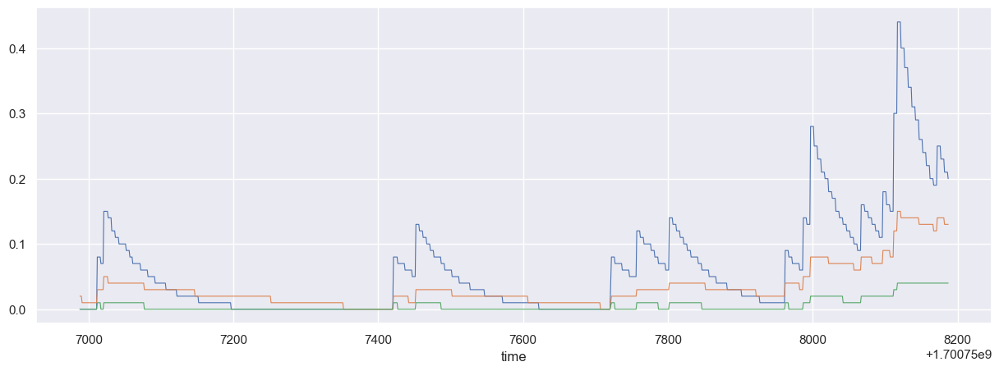

In [7]:
sns.set(rc={'figure.figsize':(15, 5)})
df_bd_lab["node_load1_192.168.56.2:9100"].plot(linewidth=0.8)
df_bd_lab["node_load5_192.168.56.2:9100"].plot(linewidth=0.8)
df_bd_lab["node_load15_192.168.56.2:9100"].plot(linewidth=0.8)
# df_bd_lab["node_load1_10.211.55.101:9100"].plot(linewidth=0.8)

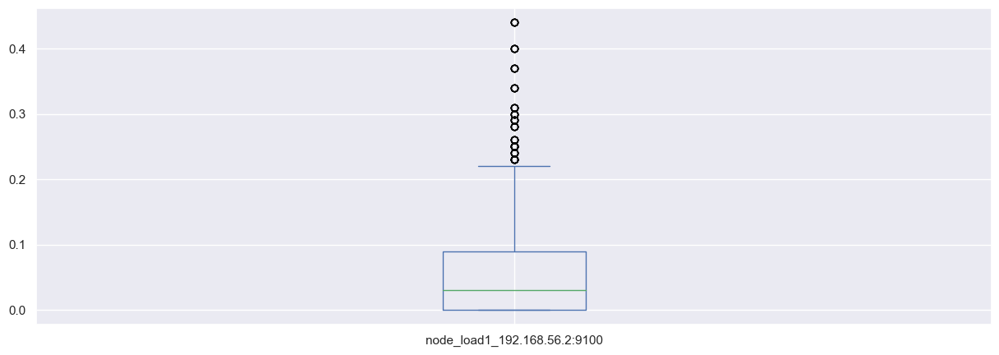

In [8]:
df_bd_lab["node_load1_192.168.56.2:9100"].plot.box();

In [9]:
df_bd_lab.columns

Index(['node_arp_entries_192.168.56.2:9100',
       'node_boot_time_seconds_192.168.56.2:9100',
       'node_context_switches_total_192.168.56.2:9100',
       'node_cpu_guest_seconds_total_192.168.56.2:9100',
       'node_cpu_seconds_total_192.168.56.2:9100',
       'node_disk_io_now_192.168.56.2:9100',
       'node_disk_io_time_seconds_total_192.168.56.2:9100',
       'node_disk_io_time_weighted_seconds_total_192.168.56.2:9100',
       'node_disk_read_bytes_total_192.168.56.2:9100',
       'node_disk_read_time_seconds_total_192.168.56.2:9100',
       ...
       'node_timex_tai_offset_seconds_192.168.56.2:9100',
       'node_timex_tick_seconds_192.168.56.2:9100',
       'node_uname_info_192.168.56.2:9100',
       'node_vmstat_oom_kill_192.168.56.2:9100',
       'node_vmstat_pgfault_192.168.56.2:9100',
       'node_vmstat_pgmajfault_192.168.56.2:9100',
       'node_vmstat_pgpgin_192.168.56.2:9100',
       'node_vmstat_pgpgout_192.168.56.2:9100',
       'node_vmstat_pswpin_192.168.56.2:9

<AxesSubplot: xlabel='time'>

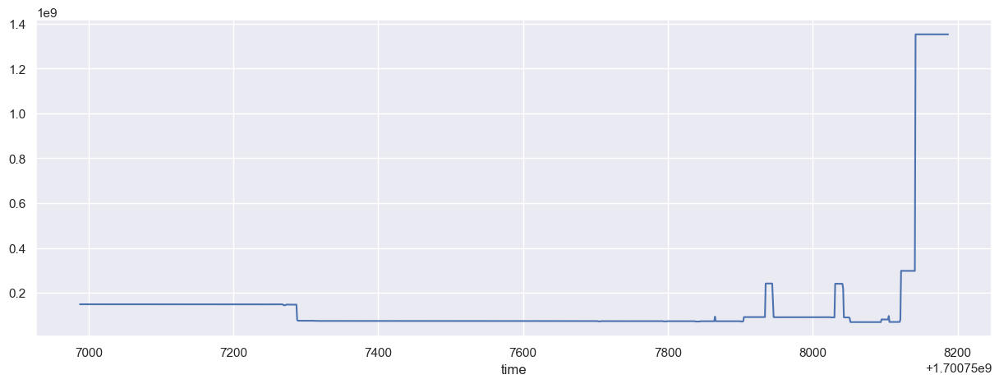

In [10]:
df_bd_lab["node_memory_MemFree_bytes_192.168.56.2:9100"].plot()

In [11]:
# df_bd_lab.fillna(0.0, inplace=True)
df_bd_lab.dropna(axis=1, inplace=True)

In [12]:
df_bd_lab.shape

(1194, 193)

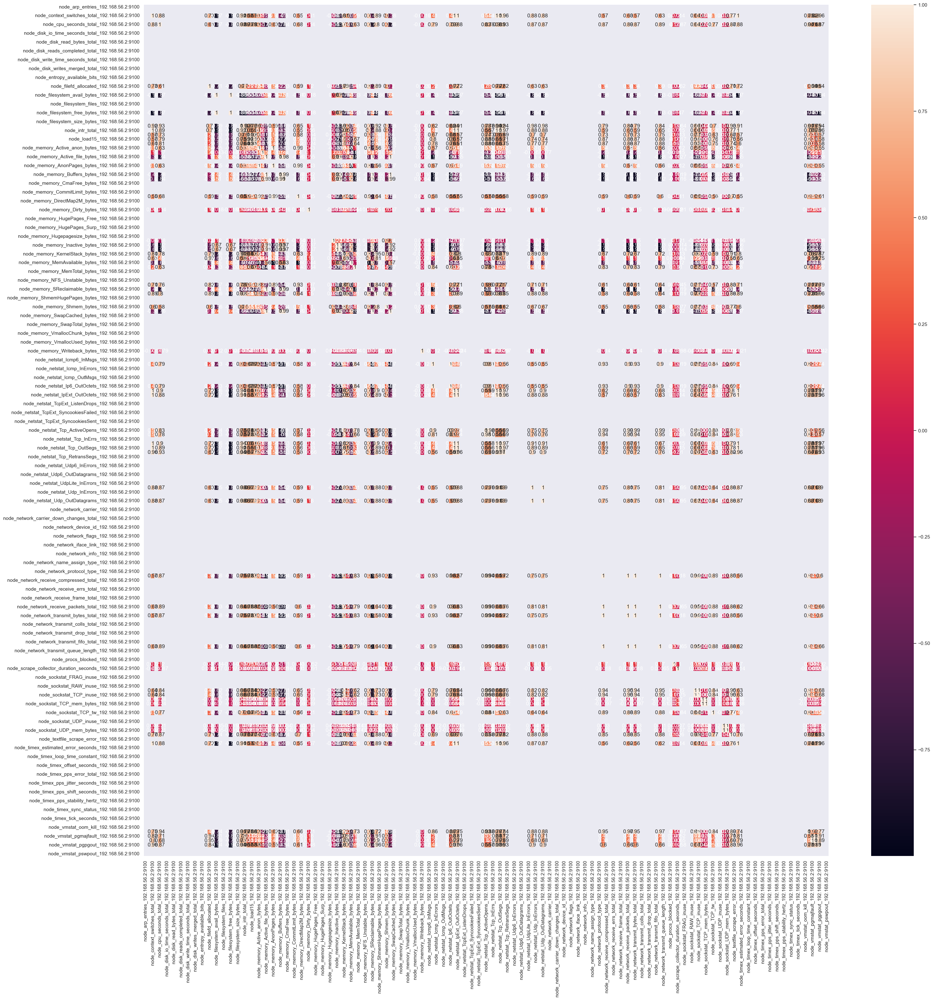

In [13]:
# Pearson correlation
plt.subplots(figsize=(35, 35))
sns.heatmap(df_bd_lab.corr(), annot=True)
plt.show()

In [14]:
# Remove low variance features
uniques_au_a = df_bd_lab.apply(lambda x: x.nunique())
rm_columns = []
for uindex, uvalue in uniques_au_a.items():
    if uvalue == 1:
        rm_columns.append(uindex)

print("Columns to be removed: {}".format(rm_columns))
print("Total: {}".format(len(rm_columns)))



Columns to be removed: ['node_arp_entries_192.168.56.2:9100', 'node_boot_time_seconds_192.168.56.2:9100', 'node_cpu_guest_seconds_total_192.168.56.2:9100', 'node_disk_io_now_192.168.56.2:9100', 'node_disk_io_time_seconds_total_192.168.56.2:9100', 'node_disk_io_time_weighted_seconds_total_192.168.56.2:9100', 'node_disk_read_bytes_total_192.168.56.2:9100', 'node_disk_read_time_seconds_total_192.168.56.2:9100', 'node_disk_reads_completed_total_192.168.56.2:9100', 'node_disk_reads_merged_total_192.168.56.2:9100', 'node_disk_write_time_seconds_total_192.168.56.2:9100', 'node_disk_writes_completed_total_192.168.56.2:9100', 'node_disk_writes_merged_total_192.168.56.2:9100', 'node_disk_written_bytes_total_192.168.56.2:9100', 'node_entropy_available_bits_192.168.56.2:9100', 'node_exporter_build_info_192.168.56.2:9100', 'node_filefd_maximum_192.168.56.2:9100', 'node_filesystem_device_error_192.168.56.2:9100', 'node_filesystem_files_192.168.56.2:9100', 'node_filesystem_files_free_192.168.56.2:910

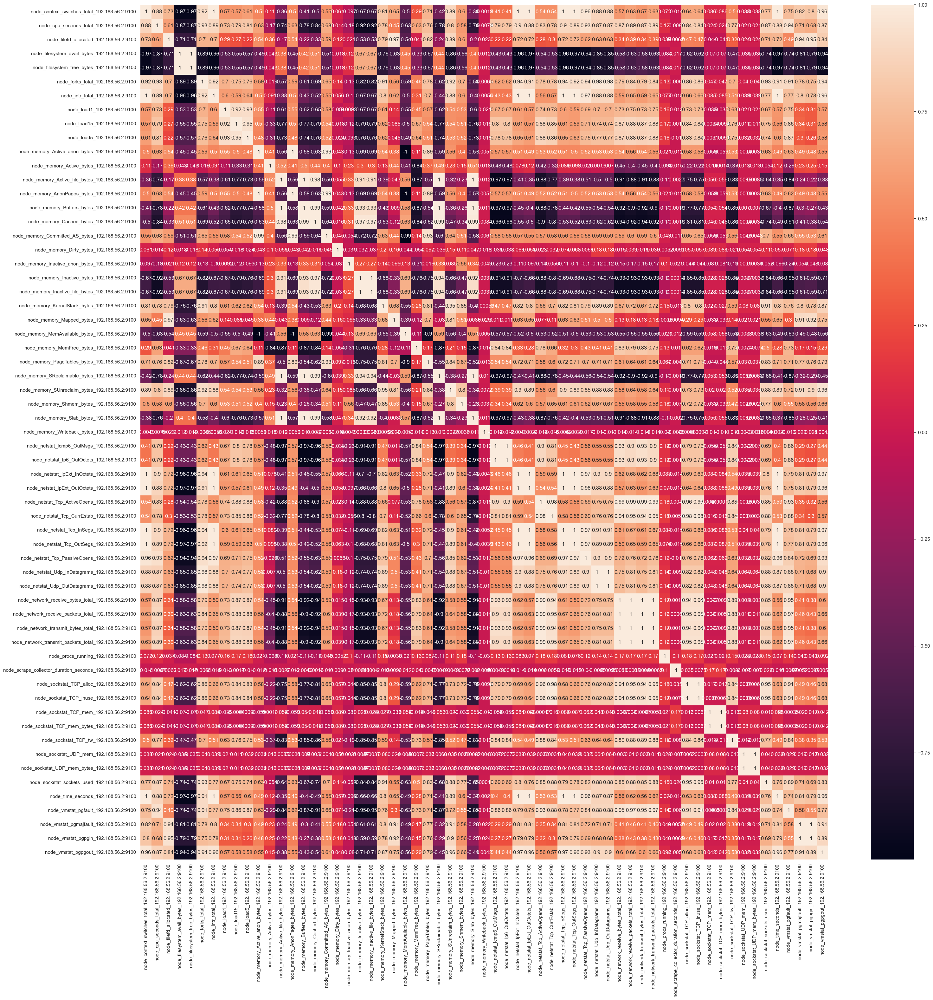

In [15]:
df_bd_lab_rm =  df_bd_lab.drop(rm_columns, axis=1)
# Pearson correlation
plt.subplots(figsize=(35, 35))
sns.heatmap(df_bd_lab_rm.corr(), annot=True)
plt.show()

In [16]:
from sklearn.ensemble import IsolationForest

In [17]:
clf = IsolationForest(
n_estimators=10,
    contamination=0.05,
    verbose=1,
)

In [18]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
df_bd_lab_rm_scaled_np = scaler.fit_transform(df_bd_lab_rm)

In [19]:
df_bd_lab_rm_scaled = pd.DataFrame(df_bd_lab_rm_scaled_np, index=df_bd_lab_rm.index, columns=df_bd_lab_rm.columns)
df_bd_lab_rm_scaled

,node_context_switches_total_192.168.56.2:9100,node_cpu_seconds_total_192.168.56.2:9100,node_filefd_allocated_192.168.56.2:9100,node_filesystem_avail_bytes_192.168.56.2:9100,node_filesystem_free_bytes_192.168.56.2:9100,node_forks_total_192.168.56.2:9100,node_intr_total_192.168.56.2:9100,node_load1_192.168.56.2:9100,node_load15_192.168.56.2:9100,node_load5_192.168.56.2:9100,...,node_sockstat_TCP_mem_bytes_192.168.56.2:9100,node_sockstat_TCP_tw_192.168.56.2:9100,node_sockstat_UDP_mem_192.168.56.2:9100,node_sockstat_UDP_mem_bytes_192.168.56.2:9100,node_sockstat_sockets_used_192.168.56.2:9100,node_time_seconds_192.168.56.2:9100,node_vmstat_pgfault_192.168.56.2:9100,node_vmstat_pgmajfault_192.168.56.2:9100,node_vmstat_pgpgin_192.168.56.2:9100,node_vmstat_pgpgout_192.168.56.2:9100
time,,,,,,,,,,,,,,,,,,,,,
1.700757e+09,0.000000,0.0,0.0625,1.0,1.0,0.0,0.000000,0.000000,0.0,0.133333,...,0.142857,0.00,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0
1.700757e+09,0.000829,0.0,0.0625,1.0,1.0,0.0,0.000674,0.000000,0.0,0.133333,...,0.142857,0.00,0.0,0.0,0.000000,0.000831,0.0,0.0,0.0,0.0
1.700757e+09,0.001556,0.0,0.0625,1.0,1.0,0.0,0.001139,0.000000,0.0,0.133333,...,0.142857,0.00,0.0,0.0,0.000000,0.001669,0.0,0.0,0.0,0.0
1.700757e+09,0.002194,0.0,0.0625,1.0,1.0,0.0,0.001800,0.000000,0.0,0.066667,...,0.142857,0.00,0.0,0.0,0.000000,0.002502,0.0,0.0,0.0,0.0
1.700757e+09,0.003054,0.0,0.0625,1.0,1.0,0.0,0.003073,0.000000,0.0,0.066667,...,0.142857,0.00,0.0,0.0,0.000000,0.003335,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1.700758e+09,0.996723,1.0,0.8750,0.0,0.0,1.0,0.997024,0.477273,1.0,0.866667,...,0.142857,0.25,0.0,0.0,0.933333,0.996663,1.0,1.0,1.0,1.0
1.700758e+09,0.997555,1.0,0.8750,0.0,0.0,1.0,0.998130,0.477273,1.0,0.866667,...,0.142857,0.25,0.0,0.0,0.933333,0.997492,1.0,1.0,1.0,1.0
1.700758e+09,0.998234,1.0,0.8750,0.0,0.0,1.0,0.998714,0.477273,1.0,0.866667,...,0.142857,0.25,0.0,0.0,0.933333,0.998325,1.0,1.0,1.0,1.0


In [20]:
clf.fit(df_bd_lab_rm_scaled)

[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.0s finished


IsolationForest(contamination=0.05, n_estimators=10, verbose=1)

In [21]:
pred = clf.predict(df_bd_lab_rm_scaled)
pred

array([ 1,  1,  1, ..., -1, -1, -1])

In [22]:
print(f"Number of anomalies {list(pred).count(-1)} from a total event count {len(list(pred)), }")

Number of anomalies 60 from a total event count (1194,)


In [23]:
anomaly_index = np.where(pred==-1)
anomaly_index

(array([ 281,  282,  283,  284,  285,  286,  287,  288,  289,  290,  294,
         295,  296,  297,  298,  299, 1102, 1125, 1126, 1127, 1128, 1129,
        1130, 1131, 1132, 1133, 1134, 1135, 1136, 1137, 1138, 1139, 1140,
        1141, 1142, 1143, 1144, 1145, 1146, 1147, 1148, 1149, 1150, 1151,
        1165, 1166, 1167, 1168, 1169, 1170, 1174, 1178, 1186, 1187, 1188,
        1189, 1190, 1191, 1192, 1193]),)

In [24]:
from sklearn.decomposition import PCA
tranformer = PCA(n_components=2)

In [25]:
tranformer.fit(df_bd_lab_rm_scaled)
X_transformed = tranformer.transform(df_bd_lab_rm_scaled)

In [26]:
X_transformed

array([[-1.91644976,  0.92929674],
       [-1.91726853,  0.92625398],
       [-1.91640588,  0.92572777],
       ...,
       [ 4.25447329,  1.97192168],
       [ 4.2554581 ,  1.97129875],
       [ 4.25603153,  1.97151943]])

In [27]:
values_2c = X_transformed[anomaly_index]
values_2c

array([[-1.41481688,  0.63037926],
       [-1.41216042,  0.63226648],
       [-1.41482272,  0.62682655],
       [-1.41183411,  0.62852335],
       [-1.53343957,  0.70069302],
       [-1.54818315,  0.70380949],
       [-1.54561134,  0.7064941 ],
       [-1.54411408,  0.70558504],
       [-1.54272564,  0.70473707],
       [-1.54120666,  0.70306148],
       [-1.4799535 ,  0.68257135],
       [-1.47963207,  0.68955674],
       [-1.47212567,  0.70777617],
       [-1.47106704,  0.70711444],
       [-1.46847067,  0.70979319],
       [-1.461353  ,  0.70297669],
       [ 2.32780362, -0.16778826],
       [ 3.04730703,  0.42509479],
       [ 3.06053277,  0.42695132],
       [ 3.07023874,  0.42390741],
       [ 3.18706655,  0.55964548],
       [ 4.15242655,  1.97376695],
       [ 4.17527252,  1.96330088],
       [ 4.17503117,  1.96035483],
       [ 4.17594283,  1.95978746],
       [ 4.17883524,  1.95716692],
       [ 4.17419642,  1.95160577],
       [ 4.17526836,  1.95093471],
       [ 4.17296105,

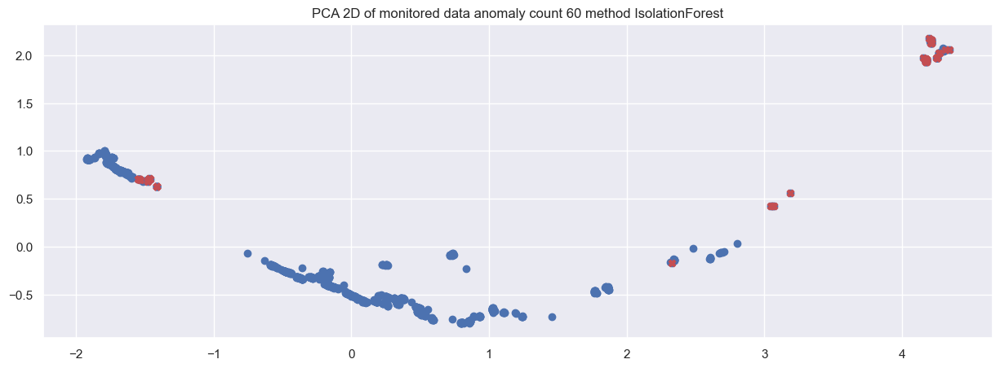

In [28]:
plt.scatter(X_transformed[:,0], X_transformed[:,1])
plt.scatter(values_2c[:,0], values_2c[:,1], color='r', marker='X')
plt.title(f"PCA 2D of monitored data anomaly count {list(pred).count(-1)} method IsolationForest")
plt.show()

In [29]:
tranformer_3d = PCA(n_components=3)
tranformer_3d.fit(df_bd_lab_rm_scaled)
X_transformed_3 = tranformer_3d.transform(df_bd_lab_rm_scaled)
values_3c = X_transformed_3[anomaly_index]
values_3c

array([[-1.41481688,  0.63037926,  0.15341799],
       [-1.41216042,  0.63226648,  0.15616554],
       [-1.41482272,  0.62682655,  0.15328099],
       [-1.41183411,  0.62852335,  0.1563658 ],
       [-1.53343957,  0.70069302,  0.30227293],
       [-1.54818315,  0.70380949,  0.30880804],
       [-1.54561134,  0.7064941 ,  0.30559819],
       [-1.54411408,  0.70558504,  0.30706528],
       [-1.54272564,  0.70473707,  0.30844009],
       [-1.54120666,  0.70306148,  0.31582155],
       [-1.4799535 ,  0.68257135,  0.31495149],
       [-1.47963207,  0.68955674,  0.3208978 ],
       [-1.47212567,  0.70777617,  0.36523275],
       [-1.47106704,  0.70711444,  0.36630729],
       [-1.46847067,  0.70979319,  0.36310234],
       [-1.461353  ,  0.70297669,  0.35959669],
       [ 2.32780362, -0.16778826,  0.61255718],
       [ 3.04730703,  0.42509479,  0.52504158],
       [ 3.06053277,  0.42695132,  0.5282815 ],
       [ 3.07023874,  0.42390741,  0.52782925],
       [ 3.18706655,  0.55964548,  0.482

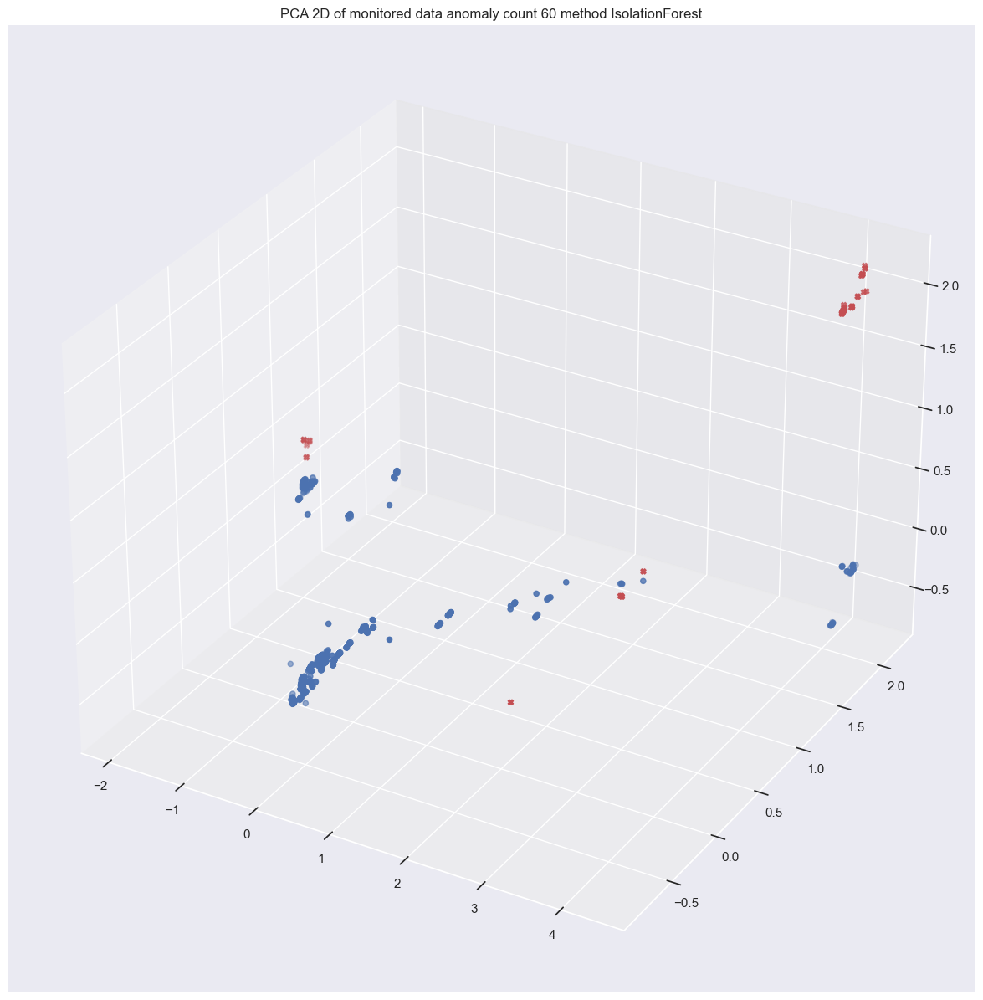

In [30]:
fig = plt.figure(figsize=(15,15))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(X_transformed_3[:,0], X_transformed_3[:,1], zs=X_transformed_3[:,2], label="Normal")
ax.scatter(values_3c[:,0], values_3c[:,1], values_3c[:,1], label="Anomaly", color='r', marker='X')
plt.title(f"PCA 2D of monitored data anomaly count {list(pred).count(-1)} method IsolationForest")
plt.show()

In [31]:
df_plot = df_bd_lab_rm_scaled
print(df_plot.columns.values)





['node_context_switches_total_192.168.56.2:9100'
 'node_cpu_seconds_total_192.168.56.2:9100'
 'node_filefd_allocated_192.168.56.2:9100'
 'node_filesystem_avail_bytes_192.168.56.2:9100'
 'node_filesystem_free_bytes_192.168.56.2:9100'
 'node_forks_total_192.168.56.2:9100' 'node_intr_total_192.168.56.2:9100'
 'node_load1_192.168.56.2:9100' 'node_load15_192.168.56.2:9100'
 'node_load5_192.168.56.2:9100'
 'node_memory_Active_anon_bytes_192.168.56.2:9100'
 'node_memory_Active_bytes_192.168.56.2:9100'
 'node_memory_Active_file_bytes_192.168.56.2:9100'
 'node_memory_AnonPages_bytes_192.168.56.2:9100'
 'node_memory_Buffers_bytes_192.168.56.2:9100'
 'node_memory_Cached_bytes_192.168.56.2:9100'
 'node_memory_Committed_AS_bytes_192.168.56.2:9100'
 'node_memory_Dirty_bytes_192.168.56.2:9100'
 'node_memory_Inactive_anon_bytes_192.168.56.2:9100'
 'node_memory_Inactive_bytes_192.168.56.2:9100'
 'node_memory_Inactive_file_bytes_192.168.56.2:9100'
 'node_memory_KernelStack_bytes_192.168.56.2:9100'
 'nod

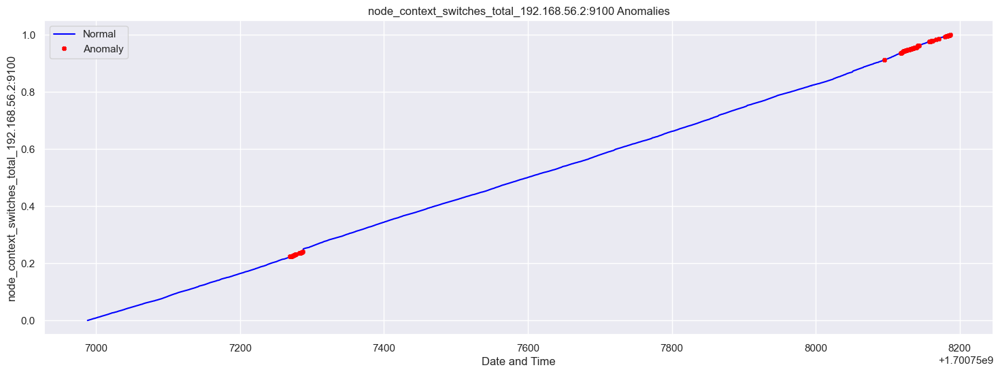

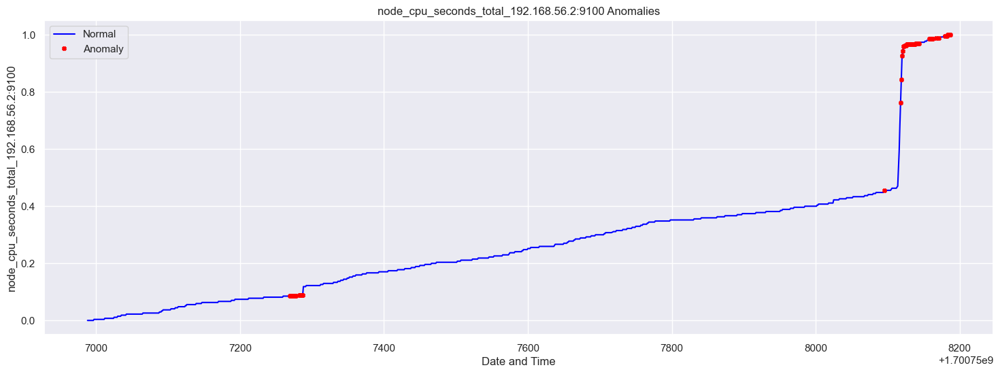

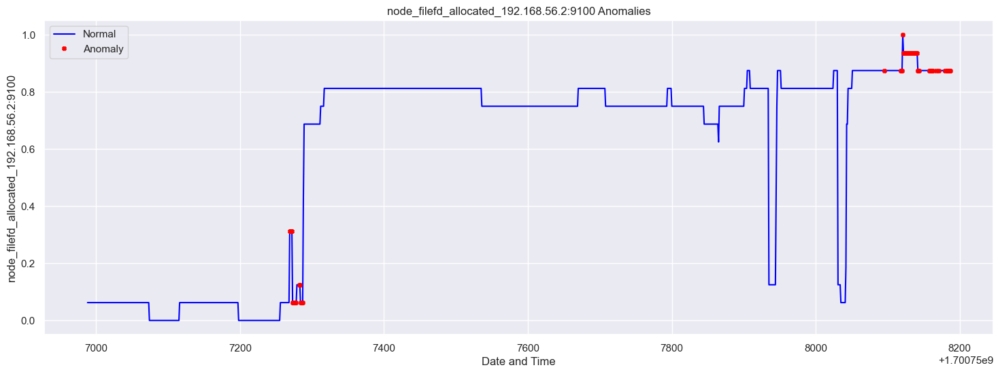

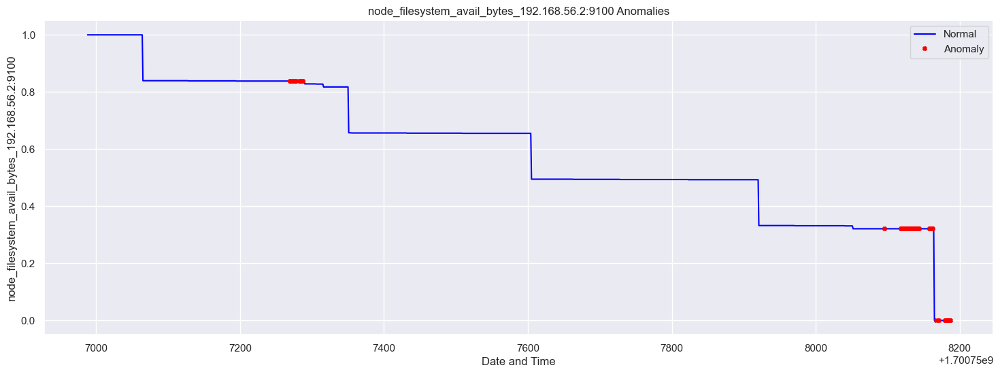

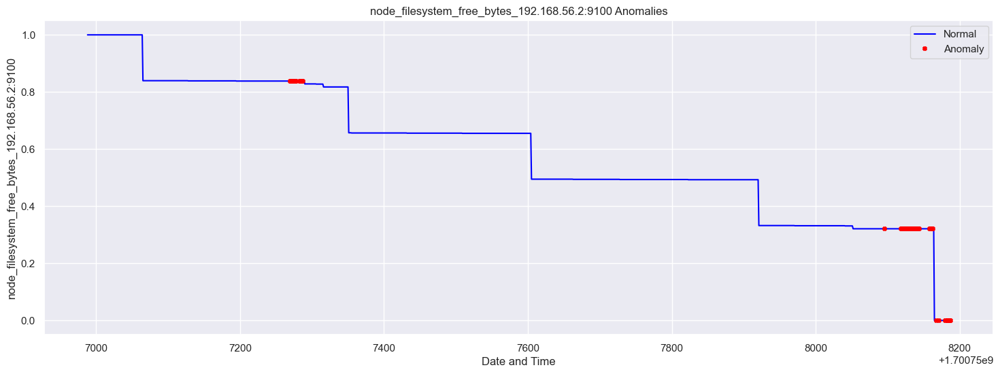

...

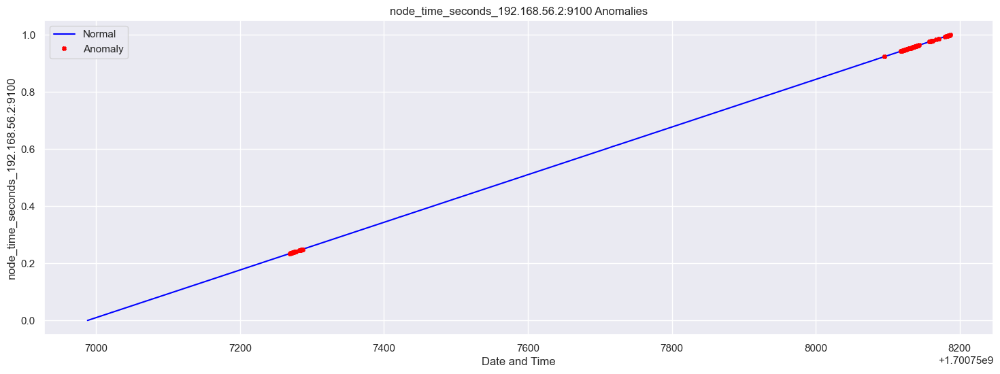

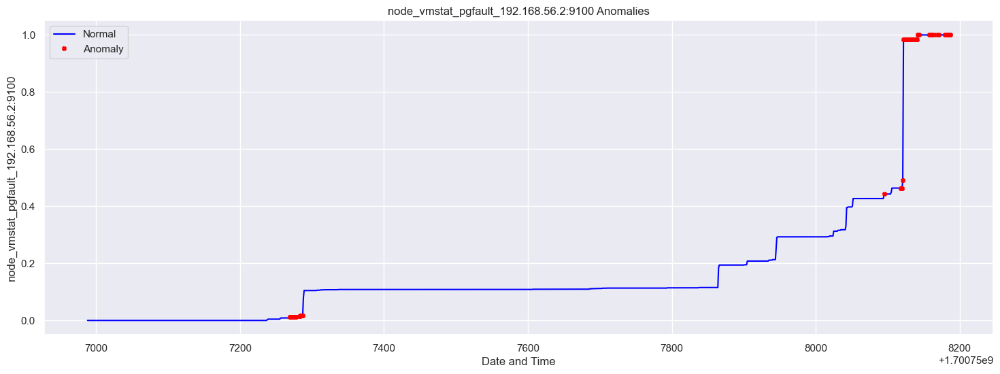

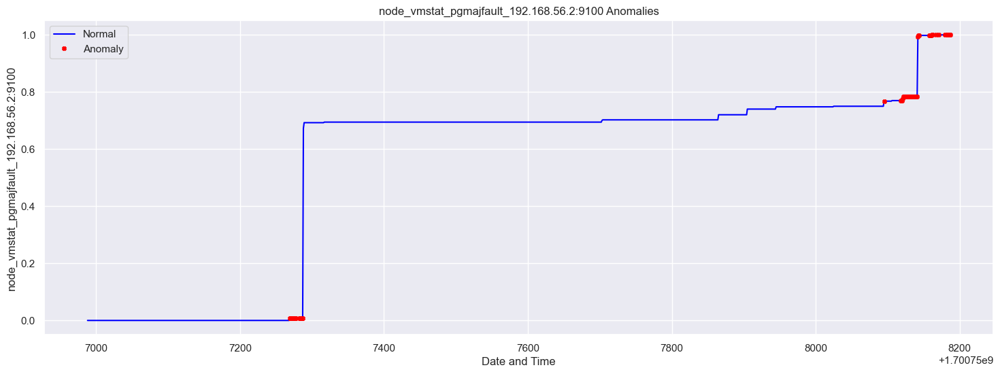

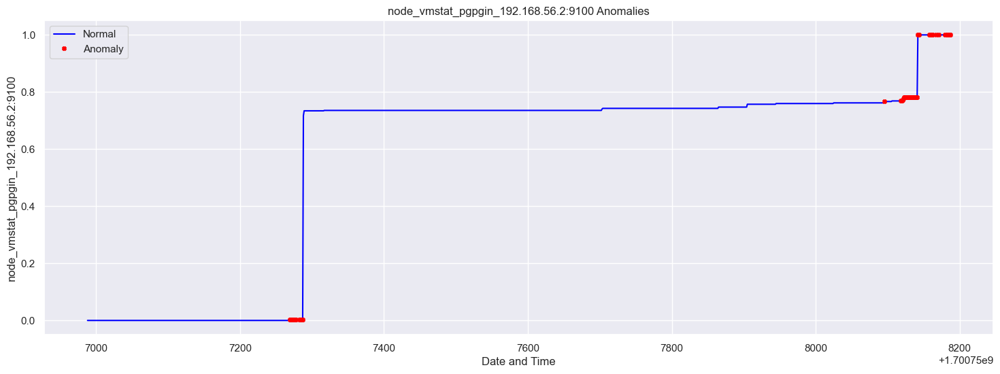

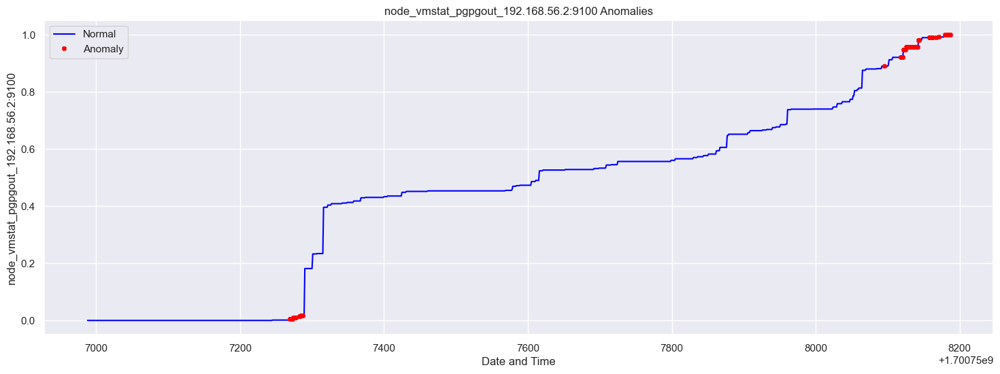

In [32]:
col_names_plt = list(df_plot.columns.values)
df_plot['anomaly'] = pred

for feature in col_names_plt:
    if feature == 'epoch' or feature == 'anomaly':
        pass
    else:
        # fig, ax = plt.subplots(figsize=(15,10))
        a = df_plot[df_plot['anomaly'] == -1] #anomaly
        _ = plt.figure(figsize=(18,6))
        _ = plt.plot(df_plot[feature], color='blue', label='Normal')
        _ = plt.plot(a[feature], linestyle='none', marker='X', color='red', markersize=4, label='Anomaly')
        _ = plt.xlabel('Date and Time')
        _ = plt.ylabel(f'{feature}')
        _ = plt.title(f'{feature} Anomalies')
        _ = plt.legend(loc='best')
        plt.show();

In [ ]:
prometheus_endpoint = '10.9.8.136'
prometheus_port = '9090'
print("Collecting data from Monitoring at: {}".format(prometheus_endpoint))
#https://prometheus.io/docs/prometheus/latest/querying/basics/
prometheus_query = {"query": '''{__name__=~"node.+"}[10m]'''}
try:
    url = '/api/v1/query'
    resp = requests.get('http://{}:{}{}'.format(prometheus_endpoint, prometheus_port, url), params=prometheus_query)
except Exception as inst:
    print("Error fetching data")

In [ ]:
df_bd_lab = prtoDF(resp.json(), verbose=True, index='time')

In [ ]:
df_bd_lab.dropna(axis=1, inplace=True)
df_bd_lab_rm =  df_bd_lab.drop(rm_columns, axis=1)

from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
df_bd_lab_rm_scaled_np = scaler.fit_transform(df_bd_lab_rm)

In [ ]:
df_bd_lab_rm_scaled = pd.DataFrame(df_bd_lab_rm_scaled_np, index=df_bd_lab_rm.index, columns=df_bd_lab_rm.columns)
df_bd_lab_rm_scaled

In [ ]:
pred_2 = clf.predict(df_bd_lab_rm_scaled)

In [ ]:
list(pred_2).count(-1)

In [ ]:
df_plot = df_bd_lab_rm_scaled
print(df_plot.columns.values)
col_names_plt = list(df_plot.columns.values)
df_plot['anomaly'] = pred_2

for feature in col_names_plt:
    if feature == 'epoch' or feature == 'anomaly':
        pass
    else:
        # fig, ax = plt.subplots(figsize=(15,10))
        a = df_plot[df_plot['anomaly'] == -1] #anomaly
        _ = plt.figure(figsize=(18,6))
        _ = plt.plot(df_plot[feature], color='blue', label='Normal')
        _ = plt.plot(a[feature], linestyle='none', marker='X', color='red', markersize=4, label='Anomaly')
        _ = plt.xlabel('Date and Time')
        _ = plt.ylabel(f'{feature}')
        _ = plt.title(f'{feature} Anomalies')
        _ = plt.legend(loc='best')
        plt.show();